# KDD: discovering and checking customer segment hypotheses

This project uses Selection, Preprocessing, Transformation, Data Mining, and Interpretation/Evaluation. `REPORT.md` also maps the original nine-step KDD account, including domain understanding, choosing the mining task and algorithm, and using discovered knowledge.

Income and spending score define the primary analysis. Age is a separate sensitivity analysis. A 30% confirmation partition remains outside model selection. Cluster labels are arbitrary, and geometric separation does not demonstrate campaign effectiveness.

**Colab instructions:** upload this `.ipynb` to Colab, use a Python 3.11+ CPU runtime, and select Runtime → Run all. The source CSV downloads from Kaggle and is checked against the saved SHA-256. If Kaggle blocks automatic download, download the named CSV from the dataset page and upload it into `cmpe_project_runs/03_kdd_mall/data/` under the current working directory (or use the exact path printed by the acquisition error). No API key is embedded. Save your executed notebook and download the resulting artifacts before ending the session.

In [1]:
import sys, subprocess, importlib.metadata as package_metadata
if sys.version_info < (3,11):raise RuntimeError("Python 3.11 or newer is required")
required={"numpy":"2.3.5","pandas":"2.2.3","scikit-learn":"1.8.0","matplotlib":"3.10.8","scipy":"1.17.0","joblib":"1.5.3"}
module_names={"numpy":"numpy","pandas":"pandas","scikit-learn":"sklearn","matplotlib":"matplotlib","scipy":"scipy","joblib":"joblib"}
mismatches=[]
for name,version in required.items():
    try:
        if package_metadata.version(name)!=version:mismatches.append(name)
    except package_metadata.PackageNotFoundError:mismatches.append(name)
already_loaded=[name for name in mismatches if module_names[name] in sys.modules]
if mismatches:
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*[f"{name}=={required[name]}" for name in mismatches]])
if already_loaded:
    raise RuntimeError("Dependencies were replaced after import: "+", ".join(already_loaded)+". Restart the runtime, then Run all.")
print("Dependency setup complete. Loaded library versions are checked in the next cell.")

Dependency setup complete. Loaded library versions are checked in the next cell.


## Setup and reproducibility

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [2]:
from pathlib import Path
import json, hashlib, urllib.request, zipfile, io, sys, platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, confusion_matrix,
    precision_score, recall_score, f1_score, mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
from sklearn.inspection import permutation_importance
SEED = 42
# Notebook runs in the current working directory; scripts run beside their source.
ROOT = Path.cwd() / "cmpe_project_runs" / '03_kdd_mall'
for folder in ["data", "artifacts", "figures", "deployment"]:
    (ROOT / folder).mkdir(exist_ok=True, parents=True)
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=["black", "0.45", "0.7"]), "font.size": 10})
def save_json(name, value):
    (ROOT / "artifacts" / name).write_text(json.dumps(value, indent=2, default=str))
def save_table(name, value):
    value.to_csv(ROOT / "artifacts" / name, index=False)
    print(name + "\n" + value.to_string(index=False))
def save_fig(name):
    plt.tight_layout()
    plt.savefig(ROOT / "figures" / name, dpi=140, bbox_inches="tight")
    plt.close()
def interval(y, pred, metric, repeats=2000, require_two_classes=False):
    rng = np.random.default_rng(SEED)
    values = []
    y, pred = np.asarray(y), np.asarray(pred)
    for _ in range(repeats):
        idx = rng.integers(0, len(y), len(y))
        if not require_two_classes or len(np.unique(y[idx])) > 1:
            values.append(metric(y[idx], pred[idx]))
    return np.quantile(values, [.025, .975]).tolist()
versions = {p: metadata.version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib", "scipy", "joblib"]}
import scipy, sklearn
loaded_versions = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
                   "matplotlib": matplotlib.__version__, "scipy": scipy.__version__, "joblib": joblib.__version__}
if loaded_versions != versions:
    raise RuntimeError("Loaded modules differ from installed distributions. Restart the runtime.")
save_json("environment.json", {"python": platform.python_version(), "packages": versions,
    "loaded_module_versions": loaded_versions, "seed": SEED})
print("Environment:", versions)



Environment: {'numpy': '2.3.5', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'matplotlib': '3.10.8', 'scipy': '1.17.0', 'joblib': '1.5.3'}


## Acquire and verify the source data

This section establishes the environment and verifies the exact source file. Dataset changes fail the checksum check so a different version cannot silently change the experiment.

In [3]:
SOURCE = 'vjchoudhary7/customer-segmentation-tutorial-in-python'
FILENAME = 'Mall_Customers.csv'
EXPECTED_SHA256 = '416a4f62a8f33841a16e1db5297f0e05d3b65b05e73632cedae58e739e1e1f77'
data_path = ROOT / "data" / FILENAME
if not data_path.exists():
    url = "https://www.kaggle.com/api/v1/datasets/download/" + SOURCE
    try:
        with urllib.request.urlopen(url, timeout=90) as response:
            archive = response.read()
        with zipfile.ZipFile(io.BytesIO(archive)) as zipped:
            data_path.write_bytes(zipped.read(FILENAME))
    except Exception as exc:
        raise RuntimeError("Download failed. Download the CSV from https://www.kaggle.com/datasets/" + SOURCE +
                           " and place it in " + str(data_path)) from exc
actual_sha = hashlib.sha256(data_path.read_bytes()).hexdigest()
if actual_sha != EXPECTED_SHA256:
    raise ValueError("Source checksum changed. Review the dataset revision before rerunning.")
raw = pd.read_csv(data_path)
print("Verified source:", SOURCE, "shape:", raw.shape, "SHA256:", actual_sha)
save_json("source_validation.json", {"source": SOURCE, "sha256": actual_sha, "raw_shape": raw.shape})



Verified source: vjchoudhary7/customer-segmentation-tutorial-in-python shape: (200, 5) SHA256: 416a4f62a8f33841a16e1db5297f0e05d3b65b05e73632cedae58e739e1e1f77


## Domain understanding and Selection: define the knowledge goal

The knowledge goal is a reproducible, understandable partition in income/spending space. Select two numeric inputs and reserve unseen customers for confirmation. Customer identifiers carry no similarity meaning.

In [4]:
# Discover groups in income/spending geometry, then test reproducibility on unseen rows.
assert raw.CustomerID.is_unique
FEATURES=["Annual Income (k$)","Spending Score (1-100)"]
assert raw[FEATURES].notna().all().all() and raw[FEATURES[0]].gt(0).all() and raw[FEATURES[1]].between(1,100).all()
df=raw.copy();X=df[FEATURES]
train_ids,test_ids=train_test_split(df.index,test_size=.3,random_state=SEED)
save_json("knowledge_objectives.json",{"goal":"Generate interpretable hypotheses about customer segments",
    "criteria":"Discovery silhouette maximum with minimum cluster share 5%; confirmation silhouette >0.40 and median subsample ARI >0.80",
    "scope":"Convenience sample; no marketing outcomes; spending-score construction not independently documented"})
save_json("data_quality.json",{"rows":len(df),"columns":len(df.columns),"discovery_n":len(train_ids),"confirmation_n":len(test_ids),
    "missing":df.isna().sum().to_dict(),"duplicate_ids":int(df.CustomerID.duplicated().sum()),
    "duplicate_feature_rows":int(X.duplicated().sum())})
pd.DataFrame({"row_index":list(train_ids)+list(test_ids),"partition":["discovery"]*len(train_ids)+["confirmation"]*len(test_ids)}).to_csv(ROOT/"artifacts/split_manifest.csv",index=False)



## Preprocessing: audit fields and retain legitimate customers

Check missingness, valid score ranges, identifier uniqueness, and numeric summaries. Keep genuine extreme customers. Exclude demographics from the primary distance space; this is a modeling choice, not proof of demographic independence.

In [5]:
# IDs identify rows; Gender and Age are excluded from the primary distance space.
save_table("discovery_descriptives.csv",df.loc[train_ids].describe().T.reset_index(names="feature"))
plt.scatter(X.loc[train_ids,FEATURES[0]],X.loc[train_ids,FEATURES[1]],color="0.25")
plt.xlabel(FEATURES[0]);plt.ylabel(FEATURES[1]);save_fig("discovery_scatter.png")
# No row is dropped solely because its income is unusual.



discovery_descriptives.csv
               feature  count      mean       std  min   25%   50%    75%   max
            CustomerID  140.0 99.614286 59.659054  1.0 46.50 101.5 152.50 200.0
                   Age  140.0 38.707143 14.133738 18.0 28.75  35.0  48.25  70.0
    Annual Income (k$)  140.0 60.285714 27.267734 15.0 39.75  62.0  78.00 137.0
Spending Score (1-100)  140.0 51.364286 26.311146  1.0 35.75  50.0  73.00  99.0


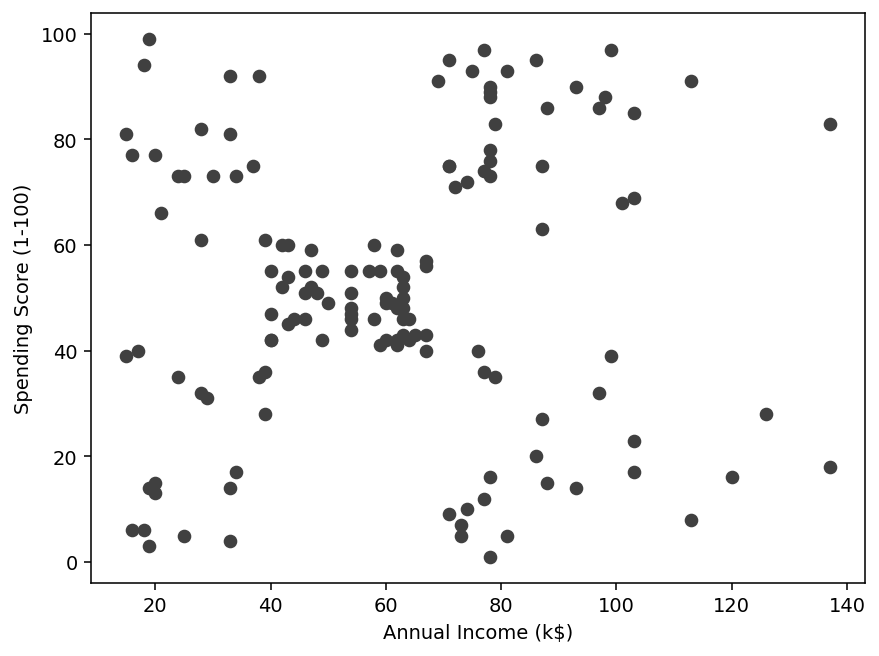

In [6]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'discovery_scatter.png')))

## Transformation: fit distance scaling on discovery rows

Learn means and standard deviations from discovery rows only. Scaling makes an income unit and a spending-score unit comparable in the distance calculation. It also changes the problem definition, which is why feature choices must be documented.

In [7]:
scale=StandardScaler().fit(X.loc[train_ids])
z=scale.transform(X.loc[train_ids]);zt=scale.transform(X.loc[test_ids])
save_json("feature_contract.json",{"required_columns":FEATURES,"excluded":["CustomerID","Gender","Age"],
    "distance":"Euclidean after discovery-only standardization","scale_mean":scale.mean_.tolist(),"scale_sd":scale.scale_.tolist()})



## Data mining: search the cluster count and compare model families

Search k=2 through 8 with KMeans and Gaussian mixtures. Rank discovery silhouette subject to minimum 5% cluster share. Report Davies–Bouldin, Calinski–Harabasz, inertia, and BIC as supporting diagnostics. BIC is meaningful within Gaussian-mixture comparisons.

In [8]:
rows=[];candidates={}
for k in range(2,9):
    for family in ["KMeans","GaussianMixture"]:
        estimator=(KMeans(n_clusters=k,n_init=20,random_state=SEED) if family=="KMeans" else
                   GaussianMixture(n_components=k,n_init=5,reg_covar=1e-6,random_state=SEED))
        labels=estimator.fit_predict(z)
        sizes=np.bincount(labels,minlength=k)
        rows.append({"family":family,"k":k,"silhouette":silhouette_score(z,labels),
            "DB_index":davies_bouldin_score(z,labels),"CH_index":calinski_harabasz_score(z,labels),
            "minimum_share":sizes.min()/len(z),"inertia":estimator.inertia_ if family=="KMeans" else np.nan,
            "BIC":estimator.bic(z) if family=="GaussianMixture" else np.nan})
        candidates[(family,k)]=estimator
results=pd.DataFrame(rows)
save_table("cluster_search.csv",results)
eligible=results[results.minimum_share>=.05].sort_values(["silhouette","k"],ascending=[False,True])
if eligible.empty:raise ValueError("No candidate meets the minimum cluster size. Revisit discovery design.")
best=eligible.iloc[0];family=str(best.family);k=int(best.k);model=candidates[(family,k)]
labels=model.predict(z);confirmation_labels=model.predict(zt)
for fam in ["KMeans","GaussianMixture"]:
    sub=results[results.family==fam];plt.plot(sub.k,sub.silhouette,marker="o",label=fam)
plt.xlabel("Number of clusters");plt.ylabel("Discovery silhouette");plt.legend();save_fig("cluster_search.png")



cluster_search.csv
         family  k  silhouette  DB_index   CH_index  minimum_share    inertia        BIC
         KMeans  2    0.400546  1.072964  71.669367       0.271429 184.290155        NaN
GaussianMixture  2    0.379351  0.831451  44.612259       0.121429        NaN 814.434550
         KMeans  3    0.464832  0.725728 104.437780       0.164286 110.906940        NaN
GaussianMixture  3    0.410733  0.724169  79.242829       0.121429        NaN 825.467108
         KMeans  4    0.486446  0.726338 123.980705       0.128571  74.969172        NaN
GaussianMixture  4    0.456741  0.775414 111.079164       0.135714        NaN 784.201244
         KMeans  5    0.549233  0.576889 173.798037       0.114286  45.531628        NaN
GaussianMixture  5    0.537573  0.603156 168.288460       0.114286        NaN 772.955594
         KMeans  6    0.539159  0.648043 171.798641       0.057143  37.784750        NaN
GaussianMixture  6    0.379544  1.163750 128.871983       0.071429        NaN 782.189792
  

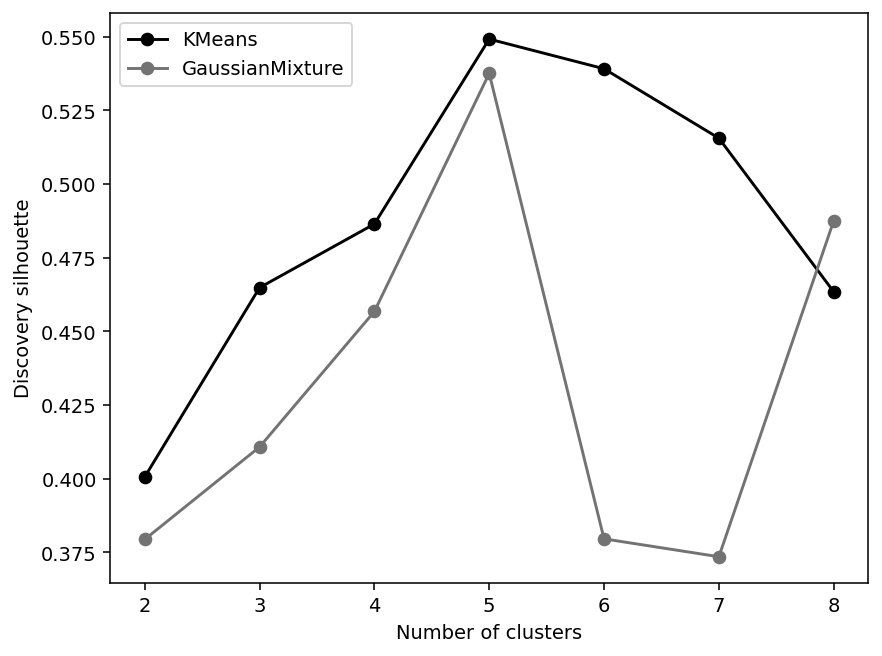

In [9]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'cluster_search.png')))

## Interpretation and evaluation: stability, null reference, and confirmation

Use the frozen pipeline and threshold once on held-out rows. Report confusion counts, precision, recall, average precision, ROC AUC, Brier loss, and bootstrap uncertainty. Group comparisons are descriptive, with denominators included. Feature importance is evaluated on validation data.

In [10]:
rng=np.random.default_rng(SEED);stability=[]
for iteration in range(30):
    idx=rng.choice(len(z),size=int(.8*len(z)),replace=False)
    alt=(KMeans(n_clusters=k,n_init=20,random_state=iteration) if family=="KMeans" else
         GaussianMixture(n_components=k,n_init=5,reg_covar=1e-6,random_state=iteration))
    subsample_scale=StandardScaler().fit(X.loc[train_ids].iloc[idx])
    alt.fit(subsample_scale.transform(X.loc[train_ids].iloc[idx]))
    stability.append(adjusted_rand_score(labels,alt.predict(subsample_scale.transform(X.loc[train_ids]))))
save_table("subsample_stability.csv",pd.DataFrame({"iteration":range(30),"ARI":stability}))
# Fixed selected family and k; this is a diagnostic reference, not a formal selection-adjusted p-value.
null=[]
for iteration in range(30):
    null_z=np.column_stack([rng.permutation(z[:,j]) for j in range(z.shape[1])])
    alt=(KMeans(n_clusters=k,n_init=10,random_state=iteration) if family=="KMeans" else
         GaussianMixture(n_components=k,n_init=3,reg_covar=1e-6,random_state=iteration))
    nl=alt.fit_predict(null_z)
    null.append(silhouette_score(null_z,nl))
save_table("null_reference.csv",pd.DataFrame({"iteration":range(30),"model_seed":range(30),"silhouette":null}))
# Adding Age changes the analytical question. Compare partitions as a sensitivity check.
za=StandardScaler().fit_transform(df.loc[train_ids,["Age"]+FEATURES])
age_estimator=(KMeans(n_clusters=k,n_init=20,random_state=SEED) if family=="KMeans" else
               GaussianMixture(n_components=k,n_init=5,reg_covar=1e-6,random_state=SEED))
age_labels=age_estimator.fit_predict(za)
assignment=pd.DataFrame({"row_index":np.r_[train_ids,test_ids],"partition":["discovery"]*len(train_ids)+["confirmation"]*len(test_ids),
    "cluster":np.r_[labels,confirmation_labels]})
save_table("cluster_assignments.csv",assignment)
centers=model.cluster_centers_ if family=="KMeans" else model.means_
center_table=pd.DataFrame(scale.inverse_transform(centers),columns=FEATURES)
center_table.insert(0,"cluster",range(k));save_table("source_unit_centers.csv",center_table)
save_table("age_sensitivity_assignments.csv",pd.DataFrame({"row_index":train_ids,"primary_cluster":labels,"age_augmented_cluster":age_labels}))
confirm_sil=float(silhouette_score(zt,confirmation_labels)) if 1<len(np.unique(confirmation_labels))<len(zt) else None
metrics={"selected_family":family,"k":k,"discovery_silhouette":float(best.silhouette),
    "confirmation_silhouette":confirm_sil,"median_subsample_ARI":float(np.median(stability)),
    "min_subsample_ARI":float(np.min(stability)),"null_silhouette_median":float(np.median(null)),
    "null_silhouette_95pct":np.quantile(null,[.025,.975]).tolist(),
    "age_sensitivity_ARI":adjusted_rand_score(labels,age_labels),
    "retrospective_gate_passed":bool(confirm_sil is not None and confirm_sil>.4 and np.median(stability)>.8),
    "stability_scope":"Assignments conditional on the selected model family and k; full family/k search is not repeated",
    "null_reference_scope":"Empirical 30-draw diagnostic range; not a confidence interval or p-value","production_approved":False}
save_json("metrics.json",metrics);print(json.dumps(metrics,indent=2))
profile=df.loc[train_ids].copy();profile["cluster"]=labels
save_table("discovery_profiles.csv",profile.groupby("cluster").agg(n=("CustomerID","size"),
    mean_income=(FEATURES[0],"mean"),mean_spending=(FEATURES[1],"mean"),mean_age=("Age","mean")).reset_index())
confirm_profile=df.loc[test_ids].copy();confirm_profile["cluster"]=confirmation_labels
save_table("confirmation_profiles.csv",confirm_profile.groupby("cluster").agg(n=("CustomerID","size"),
    mean_income=(FEATURES[0],"mean"),mean_spending=(FEATURES[1],"mean")).reset_index())
markers=["o","s","^","D","v","P","X","*"]
for group in range(k):
    mask=confirmation_labels==group
    plt.scatter(X.loc[test_ids,FEATURES[0]].to_numpy()[mask],X.loc[test_ids,FEATURES[1]].to_numpy()[mask],
                color=str(.1+.75*group/max(1,k-1)),marker=markers[group],label=f"Cluster {group}")
plt.xlabel(FEATURES[0]);plt.ylabel(FEATURES[1]);plt.legend();save_fig("confirmation_segments.png")



subsample_stability.csv
 iteration      ARI
         0 0.980510
         1 0.940587
         2 0.980510
         3 0.980302
         4 1.000000
         5 1.000000
         6 0.980510
         7 0.959681
         8 0.980510
         9 1.000000
        10 0.960956
        11 1.000000
        12 0.980302
        13 0.980302
        14 0.980510
        15 0.979123
        16 0.980302
        17 0.980510
        18 0.980302
        19 0.980510
        20 1.000000
        21 1.000000
        22 0.980510
        23 0.980510
        24 0.980302
        25 0.959681
        26 1.000000
        27 0.980510
        28 0.980510
        29 1.000000
null_reference.csv
 iteration  model_seed  silhouette
         0           0    0.376918
         1           1    0.411642
         2           2    0.404687
         3           3    0.410730
         4           4    0.399758
         5           5    0.358369
         6           6    0.372694
         7           7    0.367788
         8           8

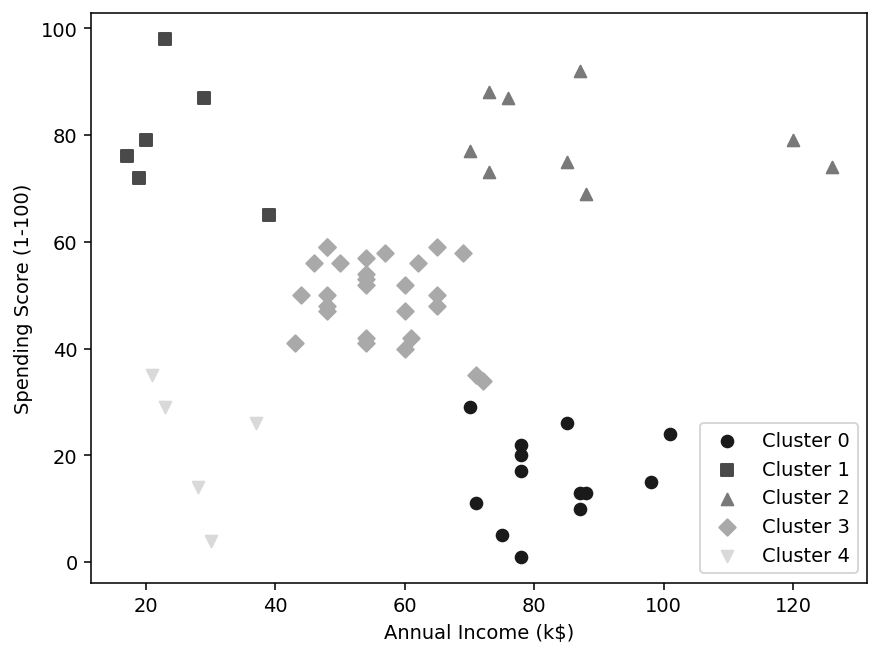

In [11]:
from IPython.display import display, Image
display(Image(filename=str(ROOT / "figures" / 'confirmation_segments.png')))

## Knowledge use: deploy a batch assignment demonstration

Deliver aggregate segment profiles and a saved assignment pipeline. Assignments are campaign hypotheses. A small randomized campaign with a control group would be needed to test whether a proposed action is useful.

In [12]:
pipeline=Pipeline([("scale",scale),("model",model)])
joblib.dump({"model":pipeline,"features":FEATURES,"task":"clustering"},ROOT/"artifacts/model.joblib")
X.loc[test_ids].head(5).to_csv(ROOT/"deployment/example_input.csv",index=False)
loaded=joblib.load(ROOT/"artifacts/model.joblib")
np.testing.assert_array_equal(loaded["model"].predict(X.loc[test_ids].head(5)),confirmation_labels[:5])
save_json("analysis_verification.json",{"disjoint_discovery_confirmation":not bool(set(train_ids)&set(test_ids)),
    "serialized_predictions_match":True,"finite_scaled_data":bool(np.isfinite(z).all()),
    "student_manual_review":"PENDING","colab_runtime_execution":"PENDING; analysis execution does not establish Colab execution"})
print("Knowledge delivered as segment hypotheses. Campaign effectiveness needs a separate controlled experiment.")


Knowledge delivered as segment hypotheses. Campaign effectiveness needs a separate controlled experiment.


## Batch scoring smoke demonstration

The following cell includes the complete scorer, so the notebook works without a repository checkout. It loads the saved pipeline, checks required columns, and scores the example rows. Replace the example CSV with a fresh input after checking the feature contract.

In [13]:
"""Run from any directory: python score.py INPUT.csv OUTPUT.csv."""
from pathlib import Path
import argparse
import csv
import json
import numpy as np
import pandas as pd
import joblib


def select_contact_queue(probability, threshold, capacity_fraction=.30):
    """Apply the frozen threshold, then cap eligible rows by risk and stable input order."""
    probability = np.asarray(probability, dtype=float)
    if not 0 <= capacity_fraction <= 1:
        raise ValueError("capacity_fraction must be within 0-1")
    eligible = np.flatnonzero(probability >= threshold)
    ranked = eligible[np.argsort(-probability[eligible], kind="stable")]
    selected = np.zeros(len(probability), dtype=bool)
    selected[ranked[:int(np.floor(capacity_fraction * len(probability)))]] = True
    return selected


def read_scoring_csv(input_csv):
    """Reject ambiguous headers and ragged records before pandas can infer an index."""
    with open(input_csv, newline="", encoding="utf-8-sig") as handle:
        reader = csv.reader(handle, strict=True)
        try:
            header = next((row for row in reader if row and not (len(row)==1 and not row[0].strip())), None)
            if header is None:
                raise ValueError("CSV has no header")
            if any(not name.strip() for name in header):
                raise ValueError("CSV header names must be nonempty")
            if len(set(header)) != len(header):
                raise ValueError("CSV contains duplicate header names")
            for row in reader:
                if not row or (len(row)==1 and not row[0].strip()):
                    continue
                if len(row) != len(header):
                    raise ValueError(f"CSV record ending at line {reader.line_num} has {len(row)} fields; expected {len(header)}")
        except csv.Error as exc:
            raise ValueError("Malformed CSV structure: " + str(exc)) from exc
    return pd.read_csv(input_csv)


def score(input_csv, output_csv, model_path=None):
    root=ROOT
    bundle=joblib.load(model_path or root/'artifacts/model.joblib')
    data=read_scoring_csv(input_csv)
    missing=set(bundle['features'])-set(data.columns)
    if missing:raise ValueError('Required columns missing: '+', '.join(sorted(missing)))
    data=data[bundle['features']].copy()
    task=bundle['task']
    if task=='classification':
        numeric=['tenure','MonthlyCharges','TotalCharges']
    else:
        numeric=bundle['features']
    for col in numeric:
        normalized=data[col].replace(r'^\s*$',np.nan,regex=True)
        converted=pd.to_numeric(normalized,errors='coerce')
        invalid=normalized.notna() & converted.isna()
        if invalid.any():raise ValueError('Non-numeric values in '+col)
        if np.isinf(converted.dropna()).any():raise ValueError('Infinite values in '+col)
        data[col]=converted
    if len(data)==0:raise ValueError('The input has no rows')
    if task=='classification':
        for col in numeric:
            if data[col].dropna().lt(0).any():raise ValueError('Negative values are invalid in '+col)
        if data['tenure'].dropna().mod(1).ne(0).any():raise ValueError('tenure must contain integer months')
    if task=='regression':
        if data[numeric].isna().all(axis=1).any():raise ValueError('At least one assay is required in every row')
        for col in numeric:
            if data[col].dropna().lt(0).any():raise ValueError('Negative values are invalid in '+col)
        if data['density'].dropna().le(0).any():raise ValueError('density must be positive')
        if not data['pH'].dropna().between(0,14).all():raise ValueError('pH must be within 0-14 for this demo')
        if not data['alcohol'].dropna().between(0,100).all():raise ValueError('alcohol must be within 0-100 percent')
    numeric_missing_count=data[numeric].isna().sum(axis=1).to_numpy()
    model=bundle['model']
    if task=='classification':
        probability=model.predict_proba(data)[:,1]
        threshold=bundle['threshold']
        contact=select_contact_queue(probability,threshold,.30)
        output=pd.DataFrame({'input_row':np.arange(len(data)),'churn_probability':probability,
                             'above_frozen_threshold':probability>=threshold,'contact_queue':contact})
    elif task=='regression':
        output=pd.DataFrame({'input_row':np.arange(len(data)),
                             'predicted_quality':np.clip(model.predict(data),*bundle['clip'])})
    else:
        if data.isna().any().any():raise ValueError('Clustering input requires complete numeric fields')
        if (data['Annual Income (k$)']<=0).any() or not data['Spending Score (1-100)'].between(1,100).all():
            raise ValueError('Income must be positive and spending score must be within 1-100')
        output=pd.DataFrame({'input_row':np.arange(len(data)),'cluster':model.predict(data)})
    output['numeric_missing_count']=numeric_missing_count
    output.to_csv(output_csv,index=False)
    print(output.to_string(index=False))
    return output



score(ROOT / "deployment/example_input.csv", ROOT / "deployment/example_output.csv")


 input_row  cluster  numeric_missing_count
         0        3                      0
         1        1                      0
         2        4                      0
         3        0                      0
         4        0                      0


## Review and submission evidence

Two internal self-review passes are documented in `reviews/INTERNAL_REVISIONS.md`. They are not Claude/GPT-5 critiques. Use `reviews/EXTERNAL_CRITIC_PROMPTS.md` to obtain two genuine external rounds for **each section**, save their responses, implement the corrections, and rerun. Complete `MANUAL_VERIFICATION.md` yourself. This notebook has not been run inside Google Colab or SAS by the assistant. Article and video files are drafts for you to publish and record.

## Export generated artifacts

Each project uses its own working directory. This ZIP includes generated tables, models, figures and scoring outputs; the full reports and source references remain in the assignment package. In Colab the ZIP is downloaded automatically.

In [14]:
import zipfile
export_path=ROOT.parent/(ROOT.name+"_generated_artifacts.zip")
with zipfile.ZipFile(export_path,"w",zipfile.ZIP_DEFLATED) as archive:
    for folder in ["artifacts","figures","deployment"]:
        for item in sorted((ROOT/folder).rglob("*")):
            if item.is_file():archive.write(item,item.relative_to(ROOT))
print("Generated artifact ZIP:",export_path)
try:
    from google.colab import files as colab_files
except ImportError:
    print("Outside Colab: copy the ZIP from the path above.")
else:
    colab_files.download(str(export_path))

Generated artifact ZIP: /workspace/scratch/2f6200312d13/review_work/executions/03_kdd_mall/cmpe_project_runs/03_kdd_mall_generated_artifacts.zip
Outside Colab: copy the ZIP from the path above.
